# 02 · The House: every district, the same error model

**In Holdout, my midterm model, Democrats win the House majority in 96% of 100,000 simulated elections (median 239 seats, 80% range 224–257), a little above Polymarket (93%) on the same snapshot (2026-10-29). The markets' price is what Holdout gives if the polls overstate Democrats nationally by about 1.1 to 1.4 points. District by district, the biggest disagreements are four Republican-held North Carolina seats (NC-03, NC-07, NC-13, NC-14), where the markets give Democrats 22 to 30 points more than Holdout, with no public district polls behind either number.**

The Senate notebook's method applied to all 435 districts. Each district's center is Split Ticket's margin, averaged with my own sponsor-adjusted polling average where a district has two or more recent polls. Errors: a national miss (t, 5 df, SD 3.0) shared with the Senate, a state miss (SD 2.7) shared by a state's districts, and a district miss that is wide where polling is thin (SD 8 with no public polls). Code in `src/midterms/house.py`; parameters in [the polling-error brief](../docs/polling-error-research.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gzip, json
from midterms import house as H
from midterms.senate import latest_snapshot

pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.titlelocation": "left",
                     "axes.titleweight": "bold"})
BLUE, RED, INK = "#2a78d6", "#e34948", "#52514e"
snap = latest_snapshot()
print("snapshot:", snap.split("snapshots/")[1])
df = H.districts(snap)

snapshot: 2026-10-29/1509/


## 1 · What each source covers

Districts are matched on a common key (`CA-22`, `AK-AL`): Split Ticket's `cd` column, Silver Bulletin's poll ids (`2026_CA-22`), Kalshi's `KXHOUSERACE-CA22-26` events (market suffix `-D` / `-R`), and Polymarket's `ca-22-house-election-winner` events (outcomes labelled `(D)`/`(R)`, else matched to the Democrat's last name).

In [2]:
cover = pd.Series({
    "Split Ticket (margin, P)": df["st_margin"].notna().sum(),
    "district polls, last 60 days (any)": (df["n_polls"] > 0).sum(),
    "district polls, 2+ (used in the center)": (df["n_polls"] >= 2).sum(),
    "Kalshi district market": df["kalshi_p_d"].notna().sum(),
    "Polymarket district market": df["pm_p_d"].notna().sum(),
}, name="districts of 435")
cover.to_frame()

,districts of 435
"Split Ticket (margin, P)",435
"district polls, last 60 days (any)",47
"district polls, 2+ (used in the center)",35
Polymarket district market,416


63 of the 112 recent district polls were sponsored by a campaign or party (about 56%). Each sponsored poll is moved 5 points against its sponsor before averaging, which puts the district polls 0.5 points to the right of the two models on average.

## 2 · The districts that decide it

In [3]:
out, s, seats = H.simulate(df, n=100_000)
cols = ["district", "held_by", "center", "st_margin", "poll_avg_adj", "n_polls", "sim_p_d", "st_p_d",
        "kalshi_p_d", "pm_p_d", "kalshi_volume"]
close = out[out["sim_p_d"].between(0.15, 0.85)].sort_values("sim_p_d")
print(f"{len(close)} districts between 15% and 85% for either side")
close[cols].round(2)

[Output left out of the public copy: it includes Kalshi prices, and Kalshi's developer agreement (v1.1, section 3) doesn't allow sharing its API data. The private repo has the full output.]


## 3 · Majority and seats

P(Democratic majority, 218+): 96.0%
Democratic seats: median 239, 80% range 224–257


Text(0.01, -0.02, 'Center: Split Ticket margins (+ district polls where 2+). Error: national t5 SD 3.0, state 2.7, district 5–8.')

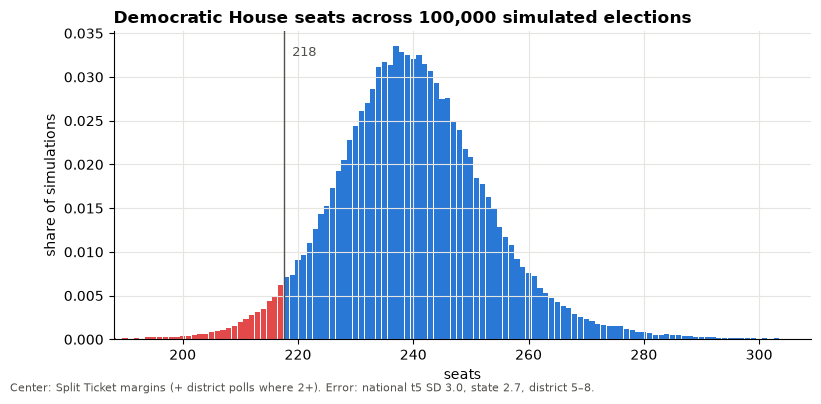

In [4]:
print(f"P(Democratic majority, 218+): {s['p_d_majority']:.1%}")
print(f"Democratic seats: median {s['seats_median']:.0f}, 80% range {s['seats_p10']:.0f}–{s['seats_p90']:.0f}")

fig, ax = plt.subplots()
vals, cnt = np.unique(seats, return_counts=True)
ax.bar(vals, cnt / cnt.sum(), width=0.9, color=np.where(vals >= H.MAJORITY, BLUE, RED))
ax.axvline(H.MAJORITY - 0.5, color=INK, lw=1)
ax.text(H.MAJORITY + 1, ax.get_ylim()[1] * 0.92, "218", color=INK, fontsize=9)
ax.set(title="Democratic House seats across 100,000 simulated elections", xlabel="seats", ylabel="share of simulations",
       xlim=(np.percentile(seats, 0.1) - 3, np.percentile(seats, 99.9) + 3))
fig.text(0.01, -0.02, "Center: Split Ticket margins (+ district polls where 2+). Error: national t5 SD 3.0, state 2.7, district 5–8.",
         fontsize=8, color=INK)

In [5]:
rows = []
for label, kw in [("blend (main)", {}), ("Split Ticket margins only", {"center": "st_margin"}),
]:
    for lean in (-1.5, 0.0, 1.5):
        _, ss, _ = H.simulate(df, nat_mean=lean, n=60_000, **kw)
        rows.append({"center": label, "polling lean (+ = D beat polls)": lean, "P(D majority)": ss["p_d_majority"],
                     "median seats": ss["seats_median"]})
pd.DataFrame(rows).pivot(index="center", columns="polling lean (+ = D beat polls)", values="P(D majority)").round(3)

polling lean (+ = D beat polls),-1.5,0.0,1.5
center,,,
Split Ticket margins only,0.923,0.966,0.985
blend (main),0.909,0.960,0.982


## 4 · The polling lean each published House number implies

As in the Senate notebook: hold the error model fixed and find the national lean that reproduces each published probability.

In [6]:
k = pd.read_csv(snap + "kalshi.csv")
kc = k[k["event"] == "CONTROLH-2026"].set_index("outcome")
pm = pd.read_csv(snap + "polymarket.csv")
pmc = pm[pm["event"] == "which-party-will-win-the-house-in-2026"].set_index("outcome")
published = {
    "DDHQ / The Hill (reported Oct 26)": 0.79,
    "Split Ticket": 0.897,
    "Kalshi": float((kc.loc["Democratic Party", "yes_bid"] + kc.loc["Democratic Party", "yes_ask"]) / 2),
    "Polymarket": float(pmc.loc["Democratic Party", "yes_price"]),
    "Silver Bulletin": 0.95, "The Economist": 0.95, "Strength In Numbers (Oct 1)": 0.99,
}
implied = {name: H.implied_lean(df, p) for name, p in published.items()}
pd.DataFrame({"P(D House)": published, "implied lean, pts (+ = polls understate D)": implied}).round(3)

,P(D House),"implied lean, pts (+ = polls understate D)"
DDHQ / The Hill (reported Oct 26),0.790,-3.162
Split Ticket,0.897,-1.733
Polymarket,0.925,-1.147
Silver Bulletin,0.950,-0.345
The Economist,0.950,-0.345
Strength In Numbers (Oct 1),0.990,2.831


Text(0.01, -0.02, 'Blend center; error model from docs/polling-error-research.md; 30k draws per point.')

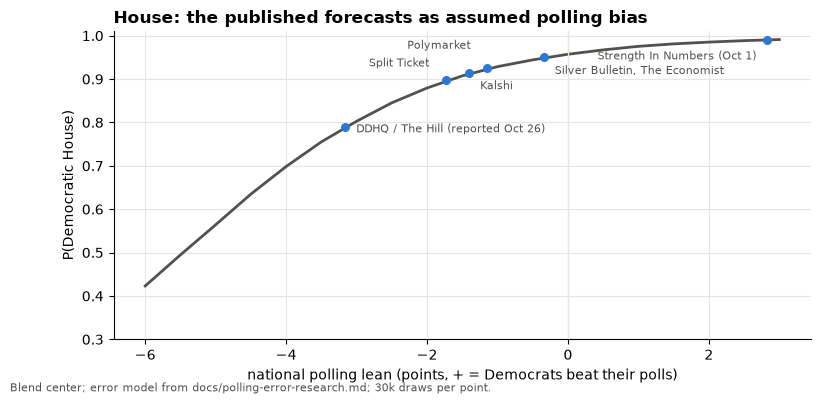

In [7]:
leans = np.linspace(-6, 3, 19)
curve = [H.simulate(df, nat_mean=x, n=30_000, seed=1)[1]["p_d_majority"] for x in leans]
fig, ax = plt.subplots()
ax.plot(leans, curve, color=INK, lw=2)
labels = {}
for name, x in implied.items():
    labels.setdefault(round(published[name], 3), (x, []))[1].append(name)
# hand-placed offsets (points) so the cluster around 0.90-0.93 stays readable
place = {"Split Ticket": (-12, 10, "right"), "Kalshi": (8, -12, "left"), "Polymarket": (-12, 14, "right"),
         "DDHQ / The Hill (reported Oct 26)": (8, -4, "left"), "Silver Bulletin, The Economist": (8, -12, "left"),
         "Strength In Numbers (Oct 1)": (-8, -14, "right")}
for pv, (x, names) in sorted(labels.items()):
    label = ", ".join(names)
    dx, dy, ha = place.get(label, (8, -4, "left"))
    ax.scatter([x], [pv], s=30, color=BLUE, zorder=3)
    ax.annotate(label, (x, pv), textcoords="offset points", xytext=(dx, dy), fontsize=8, color=INK, ha=ha)
ax.axvline(0, color="#e6e5e1", lw=1)
ax.set(xlabel="national polling lean (points, + = Democrats beat their polls)", ylabel="P(Democratic House)",
       title="House: the published forecasts as assumed polling bias", ylim=(0.3, 1.01))
fig.text(0.01, -0.02, "Blend center; error model from docs/polling-error-research.md; 30k draws per point.", fontsize=8, color=INK)

## 5 · Where the sources disagree

The districts where Holdout's simulation and the markets are furthest apart, and the markets that are too thin to mean much. These are the districts that will say the most about who was right once results are in.

In [8]:
dis = out.assign(market=out[["kalshi_p_d", "pm_p_d"]].mean(axis=1))
dis["model_minus_market"] = dis["sim_p_d"] - dis["market"]
dis = dis[dis["market"].between(0.03, 0.97) | dis["sim_p_d"].between(0.03, 0.97)]
cols = ["district", "center", "n_polls", "sim_p_d", "st_p_d", "kalshi_p_d", "pm_p_d", "kalshi_volume",
        "pm_volume", "model_minus_market"]
dis.reindex(dis["model_minus_market"].abs().sort_values(ascending=False).index)[cols].head(15).round(2)

[Output left out of the public copy: it includes Kalshi prices, and Kalshi's developer agreement (v1.1, section 3) doesn't allow sharing its API data. The private repo has the full output.]


In [9]:
priced = out[out["kalshi_p_d"].between(0.1, 0.9)]
print(f"{len(priced)} Kalshi district markets priced 10–90%; volume median {priced['kalshi_volume'].median():,.0f} contracts. "
      "The thinnest:")
priced[["district", "kalshi_p_d", "kalshi_spread", "kalshi_volume", "pm_p_d", "pm_volume", "sim_p_d"]].round(2) \
    .sort_values("kalshi_volume").head(12)

[Output left out of the public copy: it includes Kalshi prices, and Kalshi's developer agreement (v1.1, section 3) doesn't allow sharing its API data. The private repo has the full output.]


## Caveats

- The center leans on one model (Split Ticket). DDHQ's margins were used until 2026-10-29 and dropped because The Hill's robots.txt disallows AI crawlers; its published topline above is as reported (Oct 26).
- No state-lean regression for districts: post-redistricting 2024 presidential margins by district weren't in hand.
- Alaska's at-large race has an independent as the main non-Republican; a win there isn't counted toward the Democratic 218.
- District polls are few (35 districts with 2+) and mostly sponsored; the 5-point sponsor adjustment is the brief's 4–6 range, not fitted to this year.